# NYC Yellow Taxi — EDA and Data Preparation

The goal is to prepare the January 2025 NYC Yellow Taxi data for a model that predicts trip duration.

**Target:** `duration` in minutes.


## 1. Load the data

Load only the columns needed for this first booking-time model. This keeps memory usage lower.


In [1]:
from pathlib import Path
import gc

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "yellow_tripdata_2025-01.parquet"

columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "PULocationID",
    "DOLocationID",
]

df = pd.read_parquet(DATA_PATH, columns=columns)
print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (3475226, 5)


,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,PULocationID,DOLocationID
0,2025-01-01 00:18:38,2025-01-01 00:26:59,1.0,229,237
1,2025-01-01 00:32:40,2025-01-01 00:35:13,1.0,236,237
2,2025-01-01 00:44:04,2025-01-01 00:46:01,1.0,141,141
3,2025-01-01 00:14:27,2025-01-01 00:20:01,3.0,244,244
4,2025-01-01 00:21:34,2025-01-01 00:25:06,3.0,244,116


## 2. Explore the data

Check data types, basic statistics and missing values in the selected columns.


In [2]:
df.info()
display(df.describe().T)
display(df.isna().sum())


<class 'pandas.DataFrame'>
RangeIndex: 3475226 entries, 0 to 3475225
Data columns (total 5 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   tpep_pickup_datetime   datetime64[us]
 1   tpep_dropoff_datetime  datetime64[us]
 2   passenger_count        float64       
 3   PULocationID           int32         
 4   DOLocationID           int32         
dtypes: datetime64[us](2), float64(1), int32(2)
memory usage: 106.1 MB


,count,mean,min,25%,50%,75%,max,std
tpep_pickup_datetime,3475226,2025-01-17 11:02:55.910964,2024-12-31 20:47:55,2025-01-10 07:59:01,2025-01-17 15:41:33,2025-01-24 19:34:06,2025-02-01 00:00:44,NaN
tpep_dropoff_datetime,3475226,2025-01-17 11:17:56.997901,2024-12-18 07:52:40,2025-01-10 08:15:29.500000,2025-01-17 15:59:34,2025-01-24 19:48:31,2025-02-01 23:44:11,NaN
passenger_count,2935077.0,1.297859,0.0,1.0,1.0,1.0,9.0,0.75075
PULocationID,3475226.0,165.191576,1.0,132.0,162.0,234.0,265.0,64.529483
DOLocationID,3475226.0,164.125177,1.0,113.0,162.0,234.0,265.0,69.401686


tpep_pickup_datetime          0
tpep_dropoff_datetime         0
passenger_count          540149
PULocationID                  0
DOLocationID                  0
dtype: int64

## 3. Create the target variable

Trip duration is the difference between drop-off and pickup time, measured in minutes.


In [3]:
duration = (
    df["tpep_dropoff_datetime"] - df["tpep_pickup_datetime"]
).dt.total_seconds() / 60

print(duration.describe())
print("Non-positive durations:", (duration <= 0).sum())
print("Durations over 6 hours:", (duration > 360).sum())


count    3.475226e+06
mean     1.501812e+01
std      3.871358e+01
min     -5.147232e+04
25%      7.283333e+00
50%      1.170000e+01
75%      1.833333e+01
max      5.626317e+03
dtype: float64
Non-positive durations: 2051
Durations over 6 hours: 1203


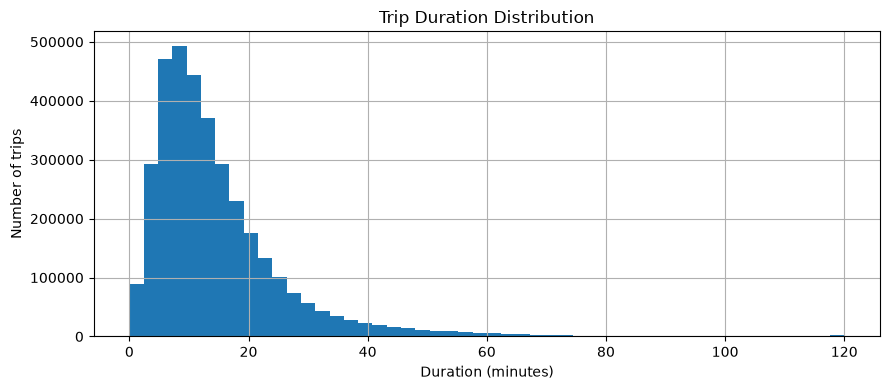

In [4]:
duration.clip(lower=0, upper=120).hist(bins=50, figsize=(9, 4))
plt.title("Trip Duration Distribution")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of trips")
plt.tight_layout()
plt.show()


## 4. Clean the data

Keep trips picked up in January 2025 with a positive duration of no more than six hours.


In [5]:
january = (
    (df["tpep_pickup_datetime"] >= "2025-01-01")
    & (df["tpep_pickup_datetime"] < "2025-02-01")
)
valid_duration = (duration > 0) & (duration <= 360)
valid_rows = january & valid_duration

# Keep only the columns needed for feature engineering and the target.
df_clean = df.loc[
    valid_rows,
    ["tpep_pickup_datetime", "passenger_count", "PULocationID", "DOLocationID"],
].copy()
df_clean["duration"] = duration.loc[valid_rows]

print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Rows retained:", round(len(df_clean) / len(df) * 100, 2), "%")

del df, duration, valid_rows, january, valid_duration
gc.collect()


Original rows: 3475226
Cleaned rows: 3471950
Rows retained: 99.91 %


5369

In [6]:
display(df_clean.head())
print("Missing values:")
display(df_clean.isna().sum())


,tpep_pickup_datetime,passenger_count,PULocationID,DOLocationID,duration
0,2025-01-01 00:18:38,1.0,229,237,8.350000
1,2025-01-01 00:32:40,1.0,236,237,2.550000
2,2025-01-01 00:44:04,1.0,141,141,1.950000
3,2025-01-01 00:14:27,3.0,244,244,5.566667
4,2025-01-01 00:21:34,3.0,244,116,3.533333


Missing values:


tpep_pickup_datetime         0
passenger_count         539916
PULocationID                 0
DOLocationID                 0
duration                     0
dtype: int64

## 5. Create model features

For a booking-time prediction, use pickup and drop-off locations, passenger count and pickup time. Actual trip distance and drop-off time are not used as model inputs.


In [7]:
pickup_hour = df_clean["tpep_pickup_datetime"].dt.hour

X = df_clean[["passenger_count", "PULocationID", "DOLocationID"]].copy()
X["pickup_hour_sin"] = np.sin(2 * np.pi * pickup_hour / 24)
X["pickup_hour_cos"] = np.cos(2 * np.pi * pickup_hour / 24)
X["pickup_day_of_week"] = df_clean["tpep_pickup_datetime"].dt.dayofweek

y = df_clean["duration"]

numerical_features = [
    "passenger_count",
    "pickup_hour_sin",
    "pickup_hour_cos",
]
categorical_features = [
    "PULocationID",
    "DOLocationID",
    "pickup_day_of_week",
]
feature_columns = numerical_features + categorical_features

print("Feature matrix:", X.shape)
print("Target:", y.shape)
display(X.head())
display(X.isna().sum())


Feature matrix: (3471950, 6)
Target: (3471950,)


C:\Users\Ahmad\AppData\Local\Temp\ipykernel_6364\242147323.py:6: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  X["pickup_day_of_week"] = df_clean["tpep_pickup_datetime"].dt.dayofweek


,passenger_count,PULocationID,DOLocationID,pickup_hour_sin,pickup_hour_cos,pickup_day_of_week
0,1.0,229,237,0.0,1.0,2
1,1.0,236,237,0.0,1.0,2
2,1.0,141,141,0.0,1.0,2
3,3.0,244,244,0.0,1.0,2
4,3.0,244,116,0.0,1.0,2


passenger_count       539916
PULocationID               0
DOLocationID               0
pickup_hour_sin            0
pickup_hour_cos            0
pickup_day_of_week         0
dtype: int64

## 6. Check pickup-time patterns


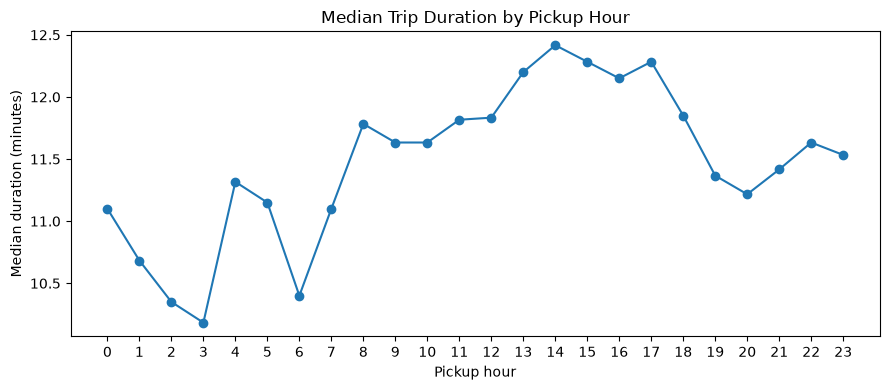

In [8]:
duration_by_hour = df_clean.groupby(
    df_clean["tpep_pickup_datetime"].dt.hour
)["duration"].median()

duration_by_hour.plot(marker="o", figsize=(9, 4))
plt.title("Median Trip Duration by Pickup Hour")
plt.xlabel("Pickup hour")
plt.ylabel("Median duration (minutes)")
plt.xticks(range(24))
plt.tight_layout()
plt.show()


## 7. Split into training and validation sets

Use an 80/20 split. The fixed random state makes the split reproducible.


In [9]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)


Training set: (2777560, 6)
Validation set: (694390, 6)


## Summary

The January taxi data has been cleaned, the initial booking-time features have been prepared, and the data has been split into training and validation sets. The next step is to build a preprocessing and Random Forest pipeline, evaluate it with RMSE, and track the experiment in MLflow.


## 8. Prepare the preprocessing and model pipeline

We use median imputation for missing passenger counts and one-hot encoding for the categorical features. The preprocessing and regressor are combined in one pipeline so the same steps are applied during training and prediction.

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import root_mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

numerical_features = [
    "passenger_count",
    "pickup_hour_sin",
    "pickup_hour_cos",
]

categorical_features = [
    "PULocationID",
    "DOLocationID",
    "pickup_day_of_week",
]

numerical_preprocessing = SimpleImputer(
    strategy="median",
    add_indicator=True,
)

categorical_preprocessing = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numerical_preprocessing, numerical_features),
    ("cat", categorical_preprocessing, categorical_features),
])

model = RandomForestRegressor(
    n_estimators=30,
    max_depth=18,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
)

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", model),
])

## 9. Train the Random Forest baseline

The dataset contains several million rows. To keep this first local experiment manageable, we train on a reproducible sample of up to 200,000 training rows and evaluate on up to 100,000 validation rows. This is a baseline experiment; we can increase the sample or tune the model later if the machine has enough memory.

In [11]:
train_sample_size = min(200_000, len(X_train))
validation_sample_size = min(100_000, len(X_val))

X_train_sample = X_train.sample(
    n=train_sample_size,
    random_state=42,
)
y_train_sample = y_train.loc[X_train_sample.index]

X_val_sample = X_val.sample(
    n=validation_sample_size,
    random_state=42,
)
y_val_sample = y_val.loc[X_val_sample.index]

print("Training sample:", X_train_sample.shape)
print("Validation sample:", X_val_sample.shape)

Training sample: (200000, 6)
Validation sample: (100000, 6)


In [12]:
pipeline.fit(X_train_sample, y_train_sample)

predictions = pipeline.predict(X_val_sample)
rmse = root_mean_squared_error(y_val_sample, predictions)

print(f"Validation RMSE: {rmse:.2f} minutes")

Validation RMSE: 9.15 minutes


## 10. Compare with a simple baseline

The mean baseline always predicts the average duration from the training sample. Comparing it with the Random Forest gives us a simple reference point.

In [13]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_sample, y_train_sample)
baseline_predictions = baseline.predict(X_val_sample)
baseline_rmse = root_mean_squared_error(
    y_val_sample,
    baseline_predictions,
)

comparison = pd.DataFrame({
    "model": ["Mean baseline", "Random Forest"],
    "RMSE": [baseline_rmse, rmse],
})

display(comparison)

,model,RMSE
0,Mean baseline,11.584737
1,Random Forest,9.147277


## 11. Check the predictions

A small sample of actual and predicted durations gives a quick check of the model output.

In [14]:
results = pd.DataFrame({
    "actual_duration": y_val_sample.iloc[:10].values,
    "predicted_duration": predictions[:10],
})

display(results.round(2))

,actual_duration,predicted_duration
0,52.25,28.78
1,1.88,13.50
2,25.63,16.26
3,14.08,12.67
4,28.65,12.67
5,43.35,35.18
6,13.32,23.73
7,5.18,12.67
8,21.10,12.67
9,7.20,12.67


## Summary

The notebook now covers data loading, basic exploration, cleaning, feature engineering, train/validation splitting, a Random Forest baseline and RMSE evaluation.

The next step is to move reusable preprocessing and training logic into Python modules under `src/`. MLflow tracking and model saving can then be added to that reusable training workflow.
